# Chất lượng dữ liệu giao dịch

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Audit Trx Nulls

Nguồn: `src/scripts/audit_trx_nulls.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/audit_trx_nulls.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Recompute raw TRX null cells, affected rows and joint patterns without filtering."""
from pathlib import Path
import json
import duckdb

ROOT = Path(__file__).resolve().parents[2]
OUT = ROOT / 'outputs/trx_null_audit_20261117'


def main():
    OUT.mkdir(parents=True, exist_ok=True)
    files = sorted((ROOT / 'data/MBD-mini/detail/trx').rglob('*.parquet'))
    before = [(str(p), p.stat().st_size, p.stat().st_mtime_ns) for p in files]
    con = duckdb.connect()
    con.execute("SET threads=2")
    con.execute("SET memory_limit='2GB'")
    con.read_parquet([p.as_posix() for p in files], hive_partitioning=True).create_view('trx')
    cols = [r[0] for r in con.execute('DESCRIBE trx').fetchall()]
    q = lambda c: '"' + c.replace('"', '""') + '"'
    null_count = ' + '.join(f'CAST({q(c)} IS NULL AS INTEGER)' for c in cols)
    expr = ', '.join(f'count(*) FILTER (WHERE {q(c)} IS NULL)' for c in cols)
    result = con.execute(f'SELECT count(*), {expr}, count(*) FILTER (WHERE ({null_count})>0) FROM trx').fetchone()
    n, counts, affected = result[0], result[1:-1], result[-1]
    import pandas as pd
    per_col = pd.DataFrame([dict(column=c, rows=n, null_n=v, null_pct=100*v/n) for c, v in zip(cols, counts)])
    per_col.to_csv(OUT / 'columns.csv', index=False)
    patterns = con.execute(f'SELECT {null_count} AS null_columns, count(*) AS rows FROM trx GROUP BY 1 ORDER BY 1').df()
    patterns['row_pct'] = patterns.rows / n * 100
    patterns.to_csv(OUT / 'null_count_per_row.csv', index=False)
    nullable = [c for c, v in zip(cols, counts) if v]
    pattern_expr = " || ',' || ".join(f"CASE WHEN {q(c)} IS NULL THEN '{c}' ELSE '' END" for c in nullable)
    con.execute(f'SELECT {pattern_expr} AS null_pattern, count(*) AS rows FROM trx GROUP BY 1 ORDER BY 2 DESC').df().to_csv(OUT / 'joint_patterns.csv', index=False)
    for group in ['fold', 'event_type']:
        table = con.execute(f'SELECT {q(group)}, count(*) AS rows, count(*) FILTER (WHERE ({null_count})>0) AS rows_any_null, {expr} FROM trx GROUP BY 1 ORDER BY 1').df()
        table.columns = [group, 'rows', 'rows_any_null'] + [c+'_null_n' for c in cols]
        table['rows_any_null_pct'] = table.rows_any_null / table.rows * 100
        table.to_csv(OUT / f'by_{group}.csv', index=False)
    old = pd.read_csv(ROOT / 'docs/report/tables/quality/raw_missing.csv')
    old = old[old.source.eq('trx')][['column', 'rows', 'missing_n']]
    check = per_col.merge(old, on='column', suffixes=('_raw', '_report'), how='outer', indicator=True)
    check['matches'] = check['_merge'].eq('both') & check.rows_raw.eq(check.rows_report) & check.null_n.eq(check.missing_n)
    check.to_csv(OUT / 'reconciliation.csv', index=False)
    assert check.matches.all(), 'Existing report differs; inspect reconciliation.csv'
    after = [(str(p), p.stat().st_size, p.stat().st_mtime_ns) for p in sorted((ROOT / 'data/MBD-mini/detail/trx').rglob('*.parquet'))]
    assert before == after
    physical_cols = [c for c in cols if c != 'fold']
    summary = dict(source='All raw detail/trx shards; no sampling, deduplication or filtering', files=len(files), rows=n,
                   columns_including_partition=len(cols), physical_columns=len(physical_cols), null_cells=sum(counts),
                   cell_null_pct=100*sum(counts)/(n*len(cols)), physical_cell_null_pct=100*sum(counts)/(n*len(physical_cols)),
                   rows_any_null=affected, rows_any_null_pct=100*affected/n, complete_rows=n-affected,
                   existing_column_report_matches=True, raw_inventory_unchanged=True,
                   definition='SQL IS NULL; zero, negative values and category codes are not treated as null. Fold is a partition column. No time grouping; timezone does not affect these counts.')
    (OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    print(per_col.to_string(index=False))
    print(patterns.to_string(index=False))
    con.close()


if __name__ == '__main__':
    main()

{
  "source": "All raw detail/trx shards; no sampling, deduplication or filtering",
  "files": 400,
  "rows": 38764930,
  "columns_including_partition": 15,
  "physical_columns": 14,
  "null_cells": 1165066,
  "cell_null_pct": 0.20036426395369905,
  "physical_cell_null_pct": 0.21467599709324897,
  "rows_any_null": 342181,
  "rows_any_null_pct": 0.8827076432228821,
  "complete_rows": 38422749,
  "existing_column_report_matches": true,
  "raw_inventory_unchanged": true,
  "definition": "SQL IS NULL; zero, negative values and category codes are not treated as null. Fold is a partition column. No time grouping; timezone does not affect these counts."
}
       column     rows  null_n  null_pct
    client_id 38764930       0  0.000000
   event_time 38764930       0  0.000000
       amount 38764930       0  0.000000
   event_type 38764930       0  0.000000
event_subtype 38764930       0  0.000000
     currency 38764930     118  0.000304
   src_type11 38764930  217361  0.560716
   src_type12 3

In [4]:
show_generated_results(__eda_started_ns, 'src/scripts/audit_trx_nulls.py')

### Kết quả: `src/scripts/audit_trx_nulls.py`

**outputs/trx_null_audit_20261117/by_event_type.csv** — 5 dòng đầu

,event_type,rows,rows_any_null,client_id_null_n,event_time_null_n,amount_null_n,event_type_null_n,event_subtype_null_n,currency_null_n,src_type11_null_n,src_type12_null_n,dst_type11_null_n,dst_type12_null_n,src_type21_null_n,src_type22_null_n,src_type31_null_n,src_type32_null_n,fold_null_n,rows_any_null_pct
0,1,16763280,33873,0,0,0,0,0,34,7725,7725,3258,3258,11026,11026,21153,21153,0,0.202067
1,3,3231,3,0,0,0,0,0,0,3,3,3,3,0,0,0,0,0,0.092851
2,4,212882,5319,0,0,0,0,0,0,0,0,0,0,3904,3904,4657,4657,0,2.498567
3,5,751,2,0,0,0,0,0,0,2,2,2,2,0,0,0,0,0,0.266312
4,6,185591,1326,0,0,0,0,0,0,201,201,1290,1290,29,29,27,27,0,0.714474


**outputs/trx_null_audit_20261117/by_fold.csv** — 5 dòng đầu

,fold,rows,rows_any_null,client_id_null_n,event_time_null_n,amount_null_n,event_type_null_n,event_subtype_null_n,currency_null_n,src_type11_null_n,src_type12_null_n,dst_type11_null_n,dst_type12_null_n,src_type21_null_n,src_type22_null_n,src_type31_null_n,src_type32_null_n,fold_null_n,rows_any_null_pct
0,0,7634228,73210,0,0,0,0,0,36,45463,45463,54202,54202,8029,8029,16159,16159,0,0.958971
1,1,8112842,74274,0,0,0,0,0,3,43463,43463,48873,48873,10311,10311,20568,20568,0,0.915511
2,2,7223703,60404,0,0,0,0,0,3,42488,42488,47760,47760,5910,5910,10423,10423,0,0.836192
3,3,8325008,65167,0,0,0,0,0,76,43667,43667,46344,46344,6856,6856,16927,16927,0,0.782786
4,4,7469149,69126,0,0,0,0,0,0,42280,42280,46645,46645,11187,11187,14919,14919,0,0.925487


**outputs/trx_null_audit_20261117/columns.csv** — 5 dòng đầu

... (4 outputs left out)

,null_columns,rows,row_pct
0,0,38422749,99.117292
1,1,82,0.000212
2,2,102029,0.263199
3,3,35,0.000090
4,4,239742,0.618451


**outputs/trx_null_audit_20261117/reconciliation.csv** — 5 dòng đầu

,column,rows_raw,null_n,null_pct,rows_report,missing_n,_merge,matches
0,amount,38764930,0,0.000000,38764930,0,both,True
1,client_id,38764930,0,0.000000,38764930,0,both,True
2,currency,38764930,118,0.000304,38764930,118,both,True
3,dst_type11,38764930,243824,0.628981,38764930,243824,both,True
4,dst_type12,38764930,243824,0.628981,38764930,243824,both,True


File kết quả khác: `outputs/trx_null_audit_20261117/summary.json`

## Audit Trx Zero Negative

Nguồn: `src/scripts/audit_trx_zero_negative.py`. Chạy các ô của phần này theo thứ tự.

In [5]:
__file__ = str(ROOT / 'src/scripts/audit_trx_zero_negative.py')
sys.argv = [__file__, '--output-dir', str(ROOT / 'outputs/notebook_runs/trx_zero_negative' / str(time.time_ns()))]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [6]:
"""Read-only audit of zeros and negatives in every numeric detail/trx field."""
import argparse
import csv
from datetime import datetime, timezone
import json
from pathlib import Path

import duckdb
import pyarrow as pa
import pyarrow.parquet as pq

ROOT = Path(__file__).resolve().parents[2]


def literal(value):
    return "'" + str(value).replace("'", "''") + "'"


def inventory(files):
    return [(str(p), p.stat().st_size, p.stat().st_mtime_ns) for p in files]


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data-root", type=Path, default=ROOT / "data/MBD-mini")
    parser.add_argument("--output-dir", type=Path, default=ROOT / "outputs/trx_zero_negative_20261116")
    args = parser.parse_args()
    source = args.data_root.resolve() / "detail/trx"
    files = sorted(source.rglob("*.parquet"))
    if not files:
        raise FileNotFoundError(source)
    before = inventory(files)
    schema = pq.ParquetFile(files[0]).schema_arrow
    numeric = [f.name for f in schema if pa.types.is_integer(f.type) or pa.types.is_floating(f.type)]
    out = args.output_dir.resolve()
    if out == args.data_root.resolve() or args.data_root.resolve() in out.parents or out in args.data_root.resolve().parents:
        raise ValueError("Audit output must not overlap raw-data tree")
    out.mkdir(parents=True, exist_ok=False)
    print(f"Scanning {len(files)} raw trx shards, {len(numeric)} numeric columns", flush=True)
    with duckdb.connect() as con:
        con.execute("SET threads=2")
        con.execute("SET memory_limit='2GB'")
        con.read_parquet([p.as_posix() for p in files], hive_partitioning=False).create_view("trx")
        expressions = ["count(*) AS rows"]
        for index, name in enumerate(numeric):
            expressions += [
                f'count(*) FILTER(WHERE "{name}"=0) AS z{index}',
                f'count(*) FILTER(WHERE "{name}"<0) AS n{index}',
                f'count(*) FILTER(WHERE "{name}" IS NULL) AS m{index}',
                f'count(*) FILTER(WHERE "{name}" IS NOT NULL AND NOT isfinite("{name}")) AS f{index}',
                f'min("{name}") FILTER(WHERE isfinite("{name}")) AS lo{index}',
                f'max("{name}") FILTER(WHERE isfinite("{name}")) AS hi{index}',
            ]
        values = con.execute("SELECT " + ", ".join(expressions) + " FROM trx").fetchall()[0]
        rows = values[0]
        columns = []
        for index, name in enumerate(numeric):
            zero, negative, missing, nonfinite, minimum, maximum = values[1 + index * 6: 7 + index * 6]
            columns.append(dict(column=name, rows=rows, zero=zero, negative=negative,
                                missing=missing, nonfinite=nonfinite, minimum=minimum, maximum=maximum))
        with (out / "numeric_columns.csv").open("w", encoding="utf-8", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(columns[0]))
            writer.writeheader()
            writer.writerows(columns)
        print(json.dumps(next(item for item in columns if item["column"] == "amount")), flush=True)
        currency = con.execute("""SELECT currency, count(*) rows,
            count(*) FILTER(WHERE amount=0) zero_amount,
            count(*) FILTER(WHERE amount<0) negative_amount,
            count(*) FILTER(WHERE amount IS NULL) missing_amount,
            min(amount)::DOUBLE minimum_amount, max(amount)::DOUBLE maximum_amount
            FROM trx GROUP BY currency ORDER BY currency NULLS LAST""").df()
        currency.to_csv(out / "amount_by_currency.csv", index=False)
        event = con.execute("""SELECT event_type, event_subtype, count(*) rows,
            count(*) FILTER(WHERE amount=0) zero_amount,
            count(*) FILTER(WHERE amount<0) negative_amount,
            min(amount)::DOUBLE minimum_amount
            FROM trx GROUP BY event_type,event_subtype ORDER BY event_type,event_subtype""").df()
        event.to_csv(out / "amount_by_event_type_subtype.csv", index=False)
        display_effect = con.execute("""SELECT
            count(*) FILTER(WHERE amount>0 AND amount<1) positive_below_one,
            count(*) FILTER(WHERE amount>0 AND round(amount::DOUBLE,2)=0) positive_rounds_to_zero_2dp,
            count(*) FILTER(WHERE amount>0 AND round(amount::DOUBLE,0)=0) positive_rounds_to_zero_0dp
            FROM trx""").fetchall()[0]
    if before != inventory(sorted(source.rglob("*.parquet"))):
        raise RuntimeError("Raw inventory changed during audit")
    report = dict(status="ready", checked_at_utc=datetime.now(timezone.utc).isoformat(),
                  scope="All raw detail/trx rows; no complete-case filters, sampling or preprocessing",
                  files=len(files), rows=rows, numeric_columns=columns,
                  amount=next(item for item in columns if item["column"] == "amount"),
                  display_effect=dict(zip(("positive_below_one", "positive_rounds_to_zero_2dp", "positive_rounds_to_zero_0dp"), display_effect)),
                  raw_modified=False,
                  inventory_note="Paths, sizes and mtimes checked before/after; not a byte checksum",
                  categorical_note="src/dst/event/currency codes are categories; zero is not automatically an error")
    (out / "summary.json").write_text(json.dumps(report, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print(json.dumps(report, ensure_ascii=False, indent=2), flush=True)


if __name__ == "__main__":
    main()

Scanning 400 raw trx shards, 12 numeric columns


{"column": "amount", "rows": 38764930, "zero": 0, "negative": 0, "missing": 0, "nonfinite": 0, "minimum": 3.021820702997502e-06, "maximum": 1370187366400.0}


{
  "status": "ready",
  "checked_at_utc": "2026-11-19T08:00:04.128472+00:00",
  "scope": "All raw detail/trx rows; no complete-case filters, sampling or preprocessing",
  "files": 400,
  "rows": 38764930,
  "numeric_columns": [
    {
      "column": "amount",
      "rows": 38764930,
      "zero": 0,
      "negative": 0,
      "missing": 0,
      "nonfinite": 0,
      "minimum": 3.021820702997502e-06,
      "maximum": 1370187366400.0
    },
    {
      "column": "event_type",
      "rows": 38764930,
      "zero": 0,
      "negative": 0,
      "missing": 0,
      "nonfinite": 0,
      "minimum": 1,
      "maximum": 56
    },
    {
      "column": "event_subtype",
      "rows": 38764930,
      "zero": 0,
      "negative": 0,
      "missing": 0,
      "nonfinite": 0,
      "minimum": 1,
      "maximum": 62
    },
    {
      "column": "currency",
      "rows": 38764930,
      "zero": 0,
      "negative": 0,
      "missing": 118,
      "nonfinite": 0,
      "minimum": 1,
      "maximum": 1

In [7]:
show_generated_results(__eda_started_ns, 'src/scripts/audit_trx_zero_negative.py')

### Kết quả: `src/scripts/audit_trx_zero_negative.py`

**outputs/notebook_runs/trx_zero_negative/1795075136016995500/amount_by_currency.csv** — 5 dòng đầu

,currency,rows,zero_amount,negative_amount,missing_amount,minimum_amount,maximum_amount
0,1,159,0,0,0,0.057873,2.028291e+07
1,3,20324,0,0,0,0.058873,1.141307e+10
2,4,3128,0,0,0,0.167505,1.716621e+09
3,5,6,0,0,0,5893.830566,3.075115e+07
4,6,82,0,0,0,88.499557,5.703855e+08


**outputs/notebook_runs/trx_zero_negative/1795075136016995500/amount_by_event_type_subtype.csv** — 5 dòng đầu

,event_type,event_subtype,rows,zero_amount,negative_amount,minimum_amount
0,1,1,111,0,0,277.732025
1,1,3,378,0,0,73.975159
2,1,5,845,0,0,0.072161
3,1,6,391,0,0,37.419315
4,1,7,61,0,0,1.713408


**outputs/notebook_runs/trx_zero_negative/1795075136016995500/numeric_columns.csv** — 5 dòng đầu

,column,rows,zero,negative,missing,nonfinite,minimum,maximum
0,amount,38764930,0,0,0,0,0.000003,1.370187e+12
1,event_type,38764930,0,0,0,0,1.000000,5.600000e+01
2,event_subtype,38764930,0,0,0,0,1.000000,6.200000e+01
3,currency,38764930,0,0,118,0,1.000000,1.700000e+01
4,src_type11,38764930,0,0,217361,0,4.000000,1.860000e+02


File kết quả khác: `outputs/notebook_runs/trx_zero_negative/1795075136016995500/summary.json`

## Audit Trx Outliers

Nguồn: `src/scripts/audit_trx_outliers.py`. Chạy các ô của phần này theo thứ tự.

In [8]:
__file__ = str(ROOT / 'src/scripts/audit_trx_outliers.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [9]:
"""Descriptive full-history outlier audit; flags are not deletion rules."""
from pathlib import Path
import json
import hashlib
import duckdb
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import RobustScaler

ROOT = Path(__file__).resolve().parents[2]
OUT = ROOT / 'outputs/trx_outliers_20261116'

In [10]:
def main():
    OUT.mkdir(exist_ok=True)
    files = sorted((ROOT / 'data/MBD-mini/detail/trx').rglob('*.parquet'))
    before = [(str(p), p.stat().st_size, p.stat().st_mtime_ns) for p in files]
    fingerprint = hashlib.sha256(json.dumps(before).encode()).hexdigest()
    c = duckdb.connect()
    c.execute("SET threads=1")
    c.execute("SET preserve_insertion_order=false")
    c.execute("SET memory_limit='2GB'")
    c.execute(f"SET temp_directory='{(OUT / 'tmp').as_posix()}'")
    c.read_parquet([p.as_posix() for p in files], hive_partitioning=False).create_view('raw')

    def export(name, sql):
        d = c.execute(sql).df()
        d.to_csv(OUT / f'{name}.csv', index=False)
        print(name, len(d), flush=True)
        return d

    # Robust reference within customer, currency and transaction subtype.
    print('Building customer behaviour references', flush=True)
    cache = OUT / 'buckets'
    cache_manifest = OUT / 'bucket_inventory.json'
    if cache.exists() and (not cache_manifest.exists() or
            json.loads(cache_manifest.read_text())['fingerprint'] != fingerprint):
        raise RuntimeError('Intermediate cache is incomplete or stale; choose a fresh output directory')
    if not cache.exists():
        c.execute(f"COPY (SELECT *,hash(client_id)%32 bucket FROM raw) TO '{cache.as_posix()}' (FORMAT PARQUET, PARTITION_BY(bucket))")
        cache_manifest.write_text(json.dumps(dict(fingerprint=fingerprint)),encoding='utf-8')
    ref_sql = '''SELECT client_id,currency,event_type,event_subtype,
        count(*) n,median(ln(amount::DOUBLE)) med,median(amount::DOUBLE) median_amount
        FROM part WHERE amount>0 AND isfinite(amount) GROUP BY ALL'''
    scale_sql = '''SELECT r.*,median(abs(ln(t.amount::DOUBLE)-r.med)) mad
        FROM part t JOIN local_ref r ON t.client_id=r.client_id
        AND t.currency IS NOT DISTINCT FROM r.currency
        AND t.event_type=r.event_type AND t.event_subtype=r.event_subtype
        WHERE r.n>=20 AND t.amount>0 AND isfinite(t.amount) GROUP BY ALL'''
    flag_sql = '''SELECT t.*,s.n reference_n,s.median_amount,
        t.amount::DOUBLE/s.median_amount ratio_to_median,
        abs(ln(t.amount::DOUBLE)-s.med)/greatest(1.4826*s.mad,ln(2)) robust_score
        FROM part t JOIN local_scales s ON t.client_id=s.client_id
        AND t.currency IS NOT DISTINCT FROM s.currency
        AND t.event_type=s.event_type AND t.event_subtype=s.event_subtype
        WHERE s.n>=20 AND t.amount>0 AND isfinite(t.amount)
        AND abs(ln(t.amount::DOUBLE)-s.med)>6*greatest(1.4826*s.mad,ln(2))'''
    repeat_sql = '''SELECT client_id,event_time,currency,amount,
        count(*) n,count(DISTINCT struct_pack(et:=event_type,es:=event_subtype,
        s11:=src_type11,s12:=src_type12,d11:=dst_type11,d12:=dst_type12,
        s21:=src_type21,s22:=src_type22,s31:=src_type31,s32:=src_type32)) variants
        FROM part GROUP BY ALL HAVING count(*)>1'''
    profile_sql = '''SELECT client_id,count(*) events,
        count(DISTINCT cast(event_time AS DATE)) active_days,
        sum(amount::DOUBLE) total_amount,median(amount::DOUBLE) median_amount,
        max(amount::DOUBLE) max_amount FROM part WHERE currency=11 GROUP BY client_id'''
    for i, folder in enumerate(sorted(cache.glob('bucket=*'))):
        c.read_parquet([p.as_posix() for p in folder.glob('*.parquet')],hive_partitioning=False).create_view('part',replace=True)
        c.execute('CREATE OR REPLACE TEMP TABLE local_ref AS '+ref_sql)
        c.execute('CREATE OR REPLACE TEMP TABLE local_scales AS '+scale_sql)
        for name, sql in [('ref','SELECT * FROM local_ref'),('flagged',flag_sql),('repeats',repeat_sql),('profiles',profile_sql)]:
            c.execute((f'CREATE TEMP TABLE {name} AS ' if i==0 else f'INSERT INTO {name} ')+sql)
        print(f'Completed customer bucket {i+1}/32',flush=True)
    export('within_customer_summary','''SELECT currency,count(*) flagged_events,
        count(DISTINCT client_id) clients FROM flagged GROUP BY currency''')
    export('within_customer_top500','SELECT * FROM flagged ORDER BY robust_score DESC LIMIT 500')
    coverage = export('reference_coverage','''SELECT sum(n) total_events,
        sum(n) FILTER(WHERE n>=20) eligible_events,count(*) reference_groups,
        count(*) FILTER(WHERE n>=20) eligible_groups FROM ref''')
    assert int(coverage.iloc[0]['total_events']) == c.execute('SELECT count(*) FROM raw').fetchall()[0][0]

    # Compare customers on the same currency; all currency-11 customers are kept.
    customers = export('customer_profiles','SELECT * FROM profiles')
    assert customers.client_id.is_unique
    cols = ['events','active_days','total_amount','median_amount','max_amount']
    x = RobustScaler().fit_transform(np.log1p(customers[cols]))
    customers['cluster'] = KMeans(n_clusters=5,n_init=10,random_state=20261116).fit_predict(x)
    customers.to_csv(OUT / 'customer_clusters_currency11.csv',index=False)
    clusters = customers.groupby('cluster').agg(clients=('client_id','size'),
        events=('events','sum'),median_events=('events','median'),
        median_total_amount=('total_amount','median'),median_ticket=('median_amount','median'))
    clusters.to_csv(OUT / 'cluster_summary_currency11.csv')
    print(clusters.to_string(),flush=True)

    print('Checking timestamp repetitions and power-of-ten signatures',flush=True)
    export('same_time_amount_summary','''SELECT currency,count(*) groups,sum(n) involved_rows,
        sum(n-1) extra_rows,sum(n-1) FILTER(WHERE variants=1) identical_extra_rows,
        count(*) FILTER(WHERE variants>1) different_metadata_groups FROM repeats GROUP BY currency''')
    export('same_time_amount_top500','SELECT * FROM repeats ORDER BY n DESC LIMIT 500')
    # 0.01% relative tolerance accommodates float32 representation; not proof of error.
    export('power10_by_currency','''SELECT currency,count(*) total,
        count(*) FILTER(WHERE abs(log10(amount::DOUBLE)-round(log10(amount::DOUBLE)))<0.00004343) near_power10,
        min(amount) min_amount,max(amount) max_amount FROM raw GROUP BY currency''')
    export('within_customer_power10_ratios','''SELECT currency,
        round(log10(ratio_to_median)) exponent,count(*) events,count(DISTINCT client_id) clients
        FROM flagged WHERE abs(log10(ratio_to_median)-round(log10(ratio_to_median)))<0.00004343
        GROUP BY ALL ORDER BY events DESC''')
    export('schema_value_checks','''SELECT count(*) rows,
        count(*) FILTER(WHERE amount IS NULL) missing_amount,
        count(*) FILTER(WHERE NOT isfinite(amount)) nonfinite_amount,
        count(*) FILTER(WHERE amount<=0) nonpositive_amount,
        count(*) FILTER(WHERE client_id IS NULL) missing_client,
        count(*) FILTER(WHERE event_time IS NULL) missing_time,
        min(event_time) first_event,max(event_time) last_event FROM raw''')
    assert before == [(str(p),p.stat().st_size,p.stat().st_mtime_ns) for p in files]
    (OUT / 'methodology.json').write_text(json.dumps(dict(
        status='ready',files=len(files),raw_modified=False,
        within_customer='client/currency/event_type/subtype; n>=20; absolute log deviation >6*max(1.4826*MAD,ln(2)); both tails',
        clustering='currency11 only; KMeans k=5 on RobustScaler(log1p(events,active_days,total,median,max)); exploratory, not validated segments',
        power10='amount or within-customer ratio within about 0.01% of 10^k; signature only, not error proof',
        limitations='Full-history descriptive references include future observations. Fit train-only or past-only references for modeling. Float32 anonymous amounts; no monetary unit mapping. Typed schema blocks textual contamination but numeric contamination needs source reconciliation.',
        coverage=coverage.to_dict(orient='records')),indent=2),encoding='utf-8')

In [11]:
if __name__ == '__main__':
    main()

Building customer behaviour references


Completed customer bucket 1/32


Completed customer bucket 2/32


Completed customer bucket 3/32


Completed customer bucket 4/32


Completed customer bucket 5/32


... (34 outputs left out)

same_time_amount_top500 0


power10_by_currency 14


within_customer_power10_ratios 4


schema_value_checks 1


In [12]:
show_generated_results(__eda_started_ns, 'src/scripts/audit_trx_outliers.py')

### Kết quả: `src/scripts/audit_trx_outliers.py`

**outputs/trx_outliers_20261116/cluster_summary_currency11.csv** — 5 dòng đầu

,cluster,clients,events,median_events,median_total_amount,median_ticket
0,0,6729,120380,7.0,3.868007e+04,2104.315186
1,1,23308,6924290,205.0,8.617092e+06,5066.288330
2,2,15433,258921,12.0,1.095128e+06,37640.046875
3,3,31353,28664723,691.0,1.448235e+08,22735.969727
4,4,21898,2755926,100.0,2.067111e+07,55916.855469


**outputs/trx_outliers_20261116/customer_clusters_currency11.csv** — 5 dòng đầu

,client_id,events,active_days,total_amount,median_amount,max_amount,cluster
0,e9a2dbd8ad5406b2d5fe6778ab9d3dda3efc2d8deb2e57...,1,1,1.360238e+05,136023.796875,1.360238e+05,2
1,3b9044014b2994d8621bd1a8b8b6d78337c0900f4e38b6...,839,492,3.357407e+07,10027.328125,2.133385e+06,3
2,6622cf4e700ab9df34e8e23c9635f88e21846109b8fc7f...,27,27,8.553185e+05,30558.976562,8.682117e+04,2
3,893f9abb2485e5c5953d2d85b812aa9b235148f40dde15...,135,123,6.348126e+07,4065.102295,7.260840e+06,1
4,c90f910fb258f1ab993a2cc82d5e5e3ca1ae9c05acec6d...,307,169,2.283907e+08,39775.667969,1.870890e+07,3


**outputs/trx_outliers_20261116/customer_profiles.csv** — 5 dòng đầu

... (14 outputs left out)

,currency,flagged_events,clients
0,3,66,30
1,4,3,2
2,11,53283,23635
3,15,49,23


**outputs/trx_outliers_20261116/within_customer_top500.csv** — 5 dòng đầu

,client_id,event_time,amount,event_type,event_subtype,currency,src_type11,src_type12,dst_type11,dst_type12,src_type21,src_type22,src_type31,src_type32,reference_n,median_amount,ratio_to_median,robust_score
0,beef56219f3ad382d982f95024a95132113cb42c70a9dd...,2021-12-14 13:30:57.163280,0.019714,21,51,11,134,278,1549,16067,19554,87,1118,19,23,1.087503e+07,1.812768e-09,29.039159
1,5c0c9cea6711151cd49c940a140cdea853567f06672bcf...,2021-11-27 10:08:31.305182,0.018878,14,46,11,134,920,306,26766,44347,2,177,84,23,8.902575e+06,2.120480e-09,28.752315
2,90b20e617ceeb379e663fa94e18e1a22b041ec3db95b3f...,2021-11-14 10:30:50.057619,0.000198,10,34,11,22,47,306,33032,23398,46,774,73,61,3.252002e+05,6.099780e-10,27.413105
3,5c0c9cea6711151cd49c940a140cdea853567f06672bcf...,2021-10-02 11:05:45.347959,0.091975,14,46,11,134,920,306,26766,44347,2,177,84,23,8.902575e+06,1.033123e-08,26.472575
4,805e94d9262fce0a2672cbd5ddb12a9ba740fe08b5849b...,2021-03-04 09:01:15.239492,0.016547,14,46,11,134,920,306,26766,29562,69,1790,19,27,4.905971e+07,3.372810e-10,25.512384


File kết quả khác: `outputs/trx_outliers_20261116/methodology.json`

## Extend Eda Trx Quality

Nguồn: `src/scripts/extend_eda_trx_quality.py`. Chạy các ô của phần này theo thứ tự.

In [13]:
__file__ = str(ROOT / 'src/scripts/extend_eda_trx_quality.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [14]:
"""Raw TRX quality, category structure and exhaustive customer concentration."""
import json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from complete_eda_figures_moscow import ROOT, OUT, BASE, publish, INDEX

In [15]:
def main():
    c=duckdb.connect();c.execute("SET memory_limit='3GB'");c.execute('SET threads=2')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp_trx'")
    path=(ROOT/'data/MBD-mini/detail/trx/**/*.parquet').as_posix()
    c.execute(f"CREATE VIEW trx AS SELECT * FROM read_parquet('{path}',hive_partitioning=true)")
    quant=c.execute("""SELECT fold,count(*) events,count(DISTINCT client_id) customers,
        count(*) FILTER(WHERE event_time=date_trunc('day',event_time)) utc_midnight,
        count(*) FILTER(WHERE event_time+INTERVAL '3 hours'=date_trunc('day',event_time+INTERVAL '3 hours')) moscow_midnight,
        count(*) FILTER(WHERE event_time=date_trunc('second',event_time)) whole_second,
        count(*) FILTER(WHERE event_time=date_trunc('minute',event_time)) whole_minute
        FROM trx GROUP BY fold ORDER BY fold""").df()
    assert quant.events.sum()==38764930
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    quant.plot.bar(x='fold',y=['events','customers'],ax=axes[0],logy=True)
    (quant.set_index('fold')[['moscow_midnight','whole_second','whole_minute']].div(quant.set_index('fold').events,axis=0)*100).plot.bar(ax=axes[1])
    axes[0].set_ylabel('Số lượng, log');axes[1].set_ylabel('% sự kiện');axes[1].legend(fontsize=8)
    publish('trx_fold_time_resolution',fig,quant,'TRX: khối lượng fold và độ phân giải timestamp',
        'Quét mọi dòng TRX; kiểm tra timestamp bằng phần nguyên ngày/phút/giây, riêng nửa đêm tính cả UTC và Moscow. '
        'Dấu bằng là chính xác trên timestamp lưu, không làm tròn.',
        'Kiểm tra mất cân bằng fold và dấu hiệu thời gian bị lượng tử hóa.',
        f'Tổng {int(quant.events.sum()):,} sự kiện; đúng nửa đêm Moscow {int(quant.moscow_midnight.sum()):,}, '
        f'đúng giây {int(quant.whole_second.sum()):,}, đúng phút {int(quant.whole_minute.sum()):,}.',
        'Timestamp tròn không chứng minh sự kiện chỉ có ngày; khối lượng fold khác có thể do khách nặng. Chưa xác nhận thời gian ETL gốc.')
    cross=c.execute('SELECT event_type,event_subtype,currency,count(*) events FROM trx GROUP BY 1,2,3').df()
    cross.to_csv(OUT/'trx_type_subtype_currency_all.csv',index=False)
    mapping=c.execute('SELECT event_subtype,count(DISTINCT event_type) parents FROM trx GROUP BY 1 ORDER BY 1').df()
    pairs=[]
    for a,b in [('event_subtype','event_type'),('src_type12','src_type11'),('dst_type12','dst_type11'),('src_type22','src_type21'),('src_type32','src_type31')]:
        r=c.execute(f'SELECT count(*) codes,sum(CASE WHEN parents>1 THEN 1 ELSE 0 END) conflicts FROM (SELECT {a},count(DISTINCT {b}) parents FROM trx WHERE {a} IS NOT NULL AND {b} IS NOT NULL GROUP BY 1)').fetchone()
        pairs.append(dict(child=a,parent=b,codes=int(r[0]),multiple_parent_codes=int(r[1] or 0)))
    pairs=pd.DataFrame(pairs)
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    pivot=cross.groupby(['event_type','event_subtype']).events.sum().unstack(fill_value=0)
    im=axes[0].imshow(np.log1p(pivot.to_numpy()),aspect='auto');fig.colorbar(im,ax=axes[0],label='log1p số sự kiện')
    axes[0].set_xlabel('event_subtype');axes[0].set_ylabel('event_type')
    xt=np.arange(0,len(pivot.columns),max(1,len(pivot.columns)//20))
    yt=np.arange(0,len(pivot.index),max(1,len(pivot.index)//18))
    axes[0].set_xticks(xt,pivot.columns[xt],rotation=90,fontsize=7)
    axes[0].set_yticks(yt,pivot.index[yt],fontsize=7)
    axes[1].barh(pairs.child+' → '+pairs.parent,pairs.multiple_parent_codes);axes[1].set_xlabel('Số mã con có nhiều mã cha')
    publish('trx_category_parent_structure',fig,pairs,'TRX: bảng chéo loại giao dịch và kiểm tra ánh xạ mã',
        'Mỗi subtype/x2 được đối chiếu số type/x1 khác nhau trên toàn nguồn; bỏ null chỉ trong phép kiểm tra ánh xạ, '
        'không xóa dòng nguồn. CSV ba chiều đầy đủ nằm tại trx_type_subtype_currency_all.csv.',
        'Xác định quan hệ ánh xạ một-cha thực nghiệm, không khẳng định phân cấp nghiệp vụ.',
        '; '.join(f'{r.child}→{r.parent}: {r.multiple_parent_codes}/{r.codes} mã nhiều cha' for r in pairs.itertuples()),
        'Một cha không khôi phục được ý nghĩa hoặc chứng minh cấu trúc hash. Null phải đọc cùng audit riêng; '
        'các mã trên trục là category, không có khoảng cách số học.')
    nullcols=['src_type11','src_type12','dst_type11','dst_type12','src_type21','src_type22','src_type31','src_type32','currency']
    expr=','.join(f'count(*) FILTER(WHERE {col} IS NULL)::DOUBLE/count(*) AS {col}' for col in nullcols)
    null=c.execute(f"SELECT date_trunc('month',event_time+INTERVAL '3 hours') AS month,count(*) events,{expr} FROM trx GROUP BY 1 ORDER BY 1").df()
    fig,ax=plt.subplots(figsize=(13,5))
    for col in nullcols: ax.plot(null.month,null[col]*100,label=col)
    ax.set_ylabel('% sự kiện null');ax.legend(ncol=3,fontsize=8);ax.grid(alpha=.2)
    publish('trx_null_drift_moscow',fig,null,'TRX: tỷ lệ null từng cột theo tháng Moscow',
        'Mẫu số là toàn bộ sự kiện từng tháng Moscow; null SQL IS NULL, không coi mã zero là null. Không loại khách/dòng có null.',
        'Kiểm tra biến động missing và các cặp null có đi cùng nhau theo thời gian.',
        f'Kiểm kê {len(null)} tháng nguồn, tổng {int(null.events.sum()):,} dòng. '
        'Các đường trùng nhau biểu thị tỷ lệ bằng nhau, chưa tự chứng minh cùng một tập dòng.',
        'Biến động null chưa xác nhận đổi schema hoặc lỗi. Đọc cùng audit tổ hợp null toàn nguồn; chưa kiểm định change point.')
    customer=c.execute("SELECT client_id,fold,count(*) events,sum(amount) FILTER(WHERE currency=11) amount11 FROM trx GROUP BY 1,2").df()
    ids=c.execute(f"SELECT client_id,fold FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/client_split/**/*.parquet',hive_partitioning=true)").df()
    p=ids.merge(customer,on=['client_id','fold'],how='left',validate='one_to_one')
    p['events']=p.events.fillna(0);p['amount11']=p.amount11.fillna(0)
    assert len(p)==100224 and p.events.sum()==38764930
    p.to_parquet(OUT/'trx_all_customer_concentration.parquet',index=False)
    fig,axes=plt.subplots(1,3,figsize=(15,4.5));summary=[]
    for metric in ['events','amount11']:
        v=np.sort(p[metric].to_numpy(float));cum=np.r_[0,np.cumsum(v)]/v.sum();pop=np.linspace(0,1,len(v)+1)
        axes[0].plot(pop,cum,label=metric)
        positive=v[v>0];axes[1].plot(positive,1-np.arange(len(positive))/len(positive),label=metric)
        gini=float(1-2*np.trapezoid(cum,pop))
        for frac in [.001,.01,.1]:
            k=int(np.ceil(len(v)*frac));summary.append(dict(metric=metric,top_fraction=frac,customers=k,share=float(v[-k:].sum()/v.sum()),gini=gini,zero_customers=int((v==0).sum())))
    axes[0].plot([0,1],[0,1],':',color='gray');axes[0].set_xlabel('Tỷ lệ khách tích lũy');axes[0].set_ylabel('Tỷ lệ khối lượng tích lũy');axes[0].legend()
    axes[1].set_xscale('log');axes[1].set_yscale('log');axes[1].set_xlabel('Khối lượng dương');axes[1].set_ylabel('CCDF trong nhóm dương');axes[1].legend()
    q=pd.DataFrame(summary)
    for metric,g in q.groupby('metric'):axes[2].plot(g.top_fraction*100,g.share*100,'o-',label=metric)
    axes[2].set_xscale('log');axes[2].set_xlabel('Top % khách');axes[2].set_ylabel('% khối lượng');axes[2].legend()
    publish('trx_customer_lorenz_ccdf',fig,q,'TRX: Lorenz, CCDF và đóng góp khách lớn',
        'Lorenz/Gini/top-share dùng toàn bộ 100.224 khách, gồm zero. CCDF chỉ nhóm dương và ghi riêng zero. '
        'Top x% chọn ceil(N*x), xếp hạng riêng theo từng chỉ tiêu. Amount chỉ currency11, đơn vị chưa xác minh.',
        'Đo mức tập trung khối lượng và độ nhạy tiềm tàng của thống kê trung bình với khách lớn.',
        '; '.join(f'{r.metric}: top {r.top_fraction*100:g}% đóng góp {r.share*100:.2f}%, Gini={r.gini:.4f}' for r in q.itertuples()),
        'Top theo amount khác top theo count. Không gọi amount là doanh thu hoặc dùng xếp hạng toàn kỳ để tạo feature quá khứ. '
        'Không loại khách lớn chỉ vì họ chi phối tổng.')
    # Missing TRX across folds, keeping all labels and full-source flags.
    labels=pd.read_parquet(BASE/'labels_any.parquet').groupby('client_id').agg(positive_months=('y','sum'),label_months=('y','size')).reset_index()
    p=p.merge(labels,on='client_id',validate='one_to_one')
    p['has_trx']=p.events>0
    group=p.groupby(['fold','has_trx']).agg(customers=('client_id','size'),positive_months=('positive_months','sum'),label_months=('label_months','sum')).reset_index()
    group['purchase_rate']=group.positive_months/group.label_months
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    group.pivot(index='fold',columns='has_trx',values='customers').plot.bar(ax=axes[0],logy=True)
    (group.pivot(index='fold',columns='has_trx',values='purchase_rate')*100).plot.bar(ax=axes[1])
    axes[0].set_ylabel('Khách, log');axes[1].set_ylabel('% khách–tháng mua')
    publish('trx_missing_population_fold_purchase',fig,group,'Khách không có TRX: phân bố fold và nhãn mua',
        'Không có TRX được xác định trên toàn lịch nguồn, chỉ dùng mô tả hồi cứu. Nhãn là toàn bộ 12 tháng mỗi khách; '
        'tỷ lệ mua=số tháng dương/tổng khách–tháng trong nhóm. Mọi khách có đúng một fold.',
        'Đối chiếu nhóm không có log với phần còn lại mà không xóa họ khỏi tổng thể.',
        f'{int((~p.has_trx).sum()):,}/{len(p):,} khách không có TRX; tổng nhãn đối soát {int(group.label_months.sum()):,} khách–tháng.',
        'Không có log toàn kỳ khác không có log trước cutoff. Tỷ lệ mô tả chưa có bootstrap và chưa điều chỉnh nguồn khác. '
        'Không khẳng định mất khách hoặc lỗi ETL.')
    c.close()
    old=pd.read_csv(OUT/'figure_index.csv');idx=pd.concat([old,pd.DataFrame(INDEX)]).drop_duplicates('figure',keep='last');idx.to_csv(OUT/'figure_index.csv',index=False)
    status=json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'))
    status['done']+=['trx_raw_fold_time_resolution','trx_category_parent_cross_tables','trx_moscow_null_drift','trx_all_customer_gini_lorenz_topshare','trx_missing_fold_purchase']
    status['figures']=len(idx)
    (OUT/'execution_status.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')

In [16]:
if __name__=='__main__':main()

Saved trx_fold_time_resolution


Saved trx_category_parent_structure


Saved trx_null_drift_moscow


Saved trx_customer_lorenz_ccdf


Saved trx_missing_population_fold_purchase


### Kết quả: `src/scripts/extend_eda_trx_quality.py`

**outputs/eda_figures_moscow/trx_category_parent_structure.png**

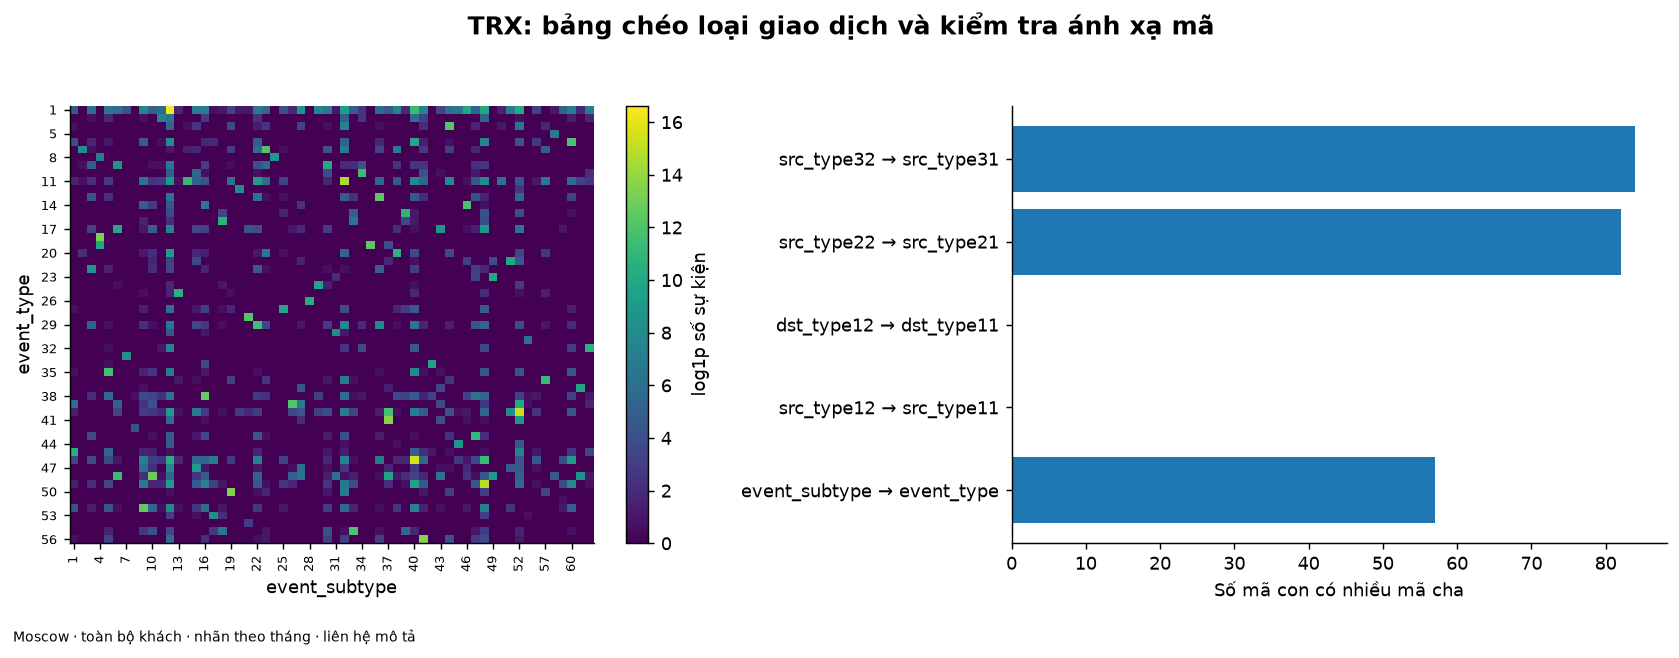

**outputs/eda_figures_moscow/trx_customer_lorenz_ccdf.png**

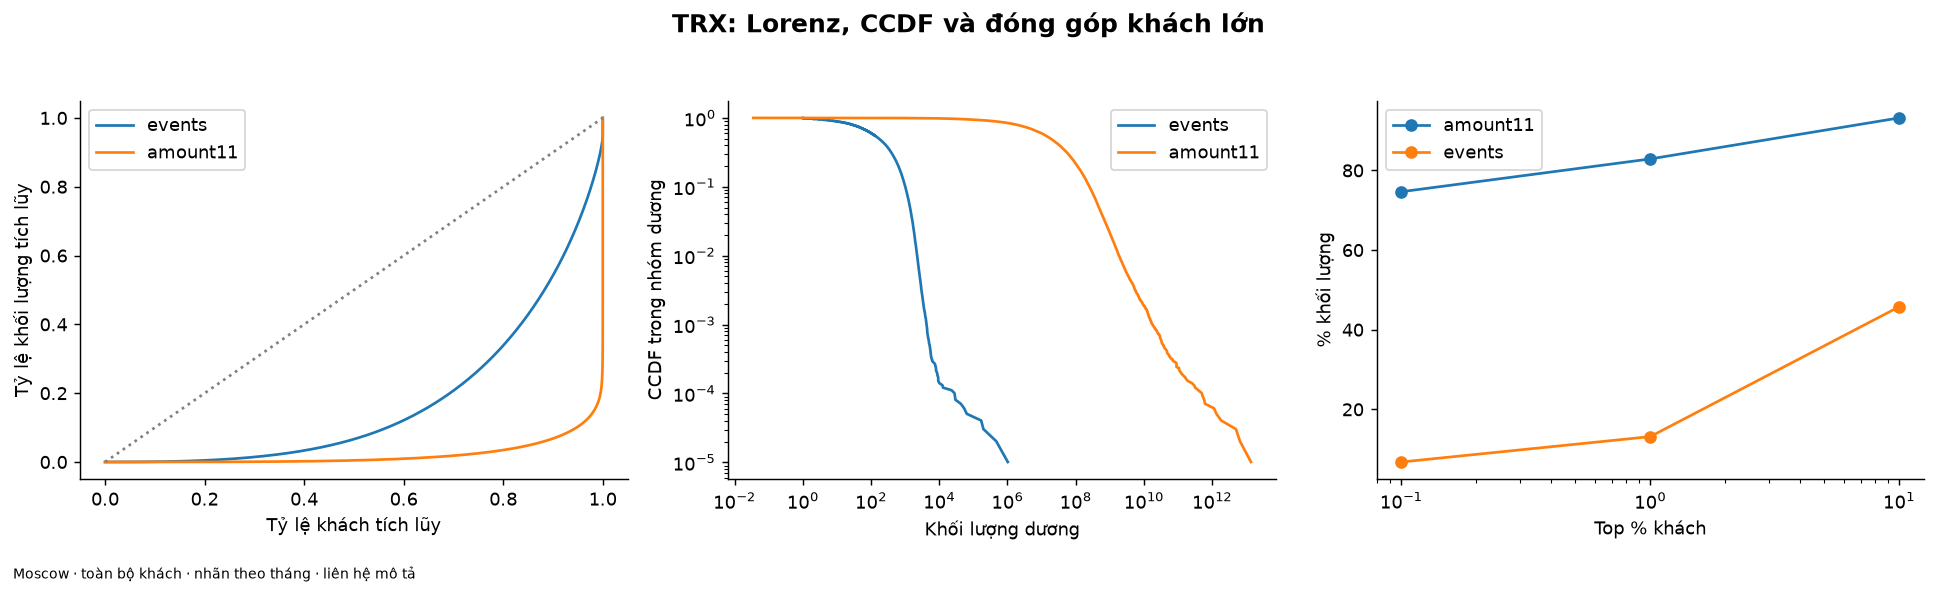

**outputs/eda_figures_moscow/trx_fold_time_resolution.png**

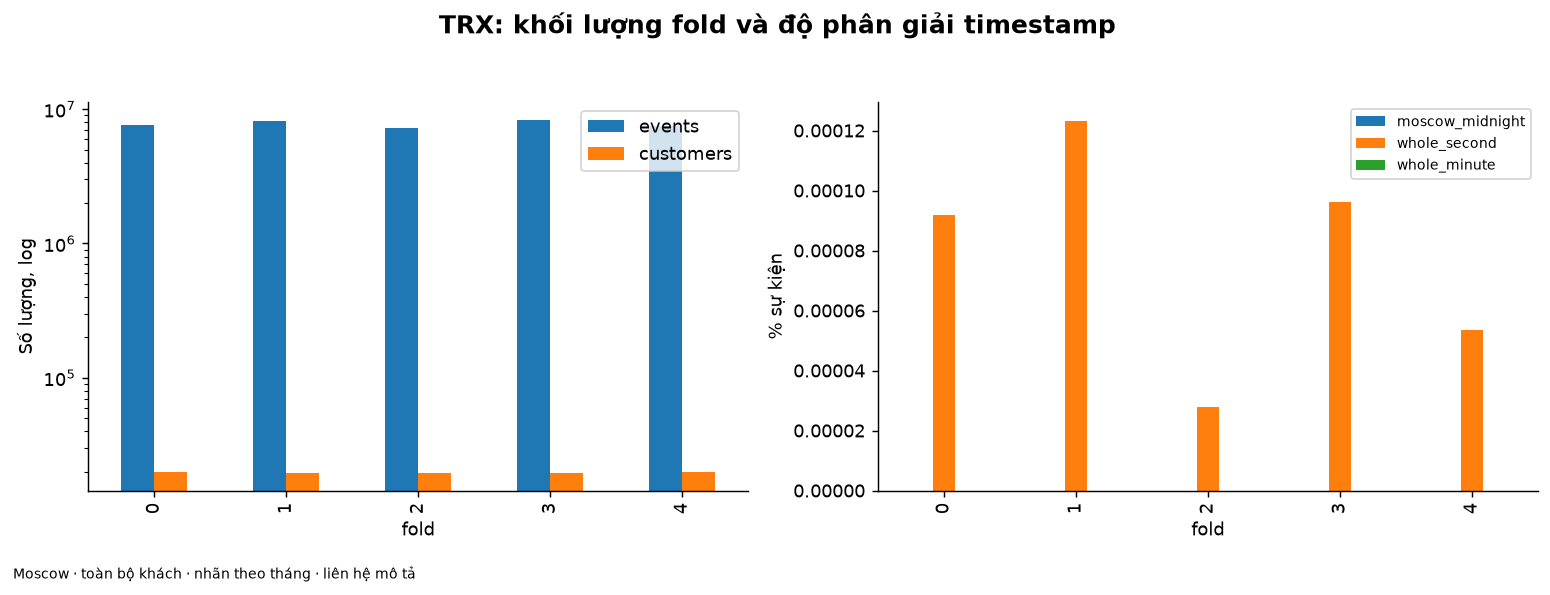

**outputs/eda_figures_moscow/trx_missing_population_fold_purchase.png**

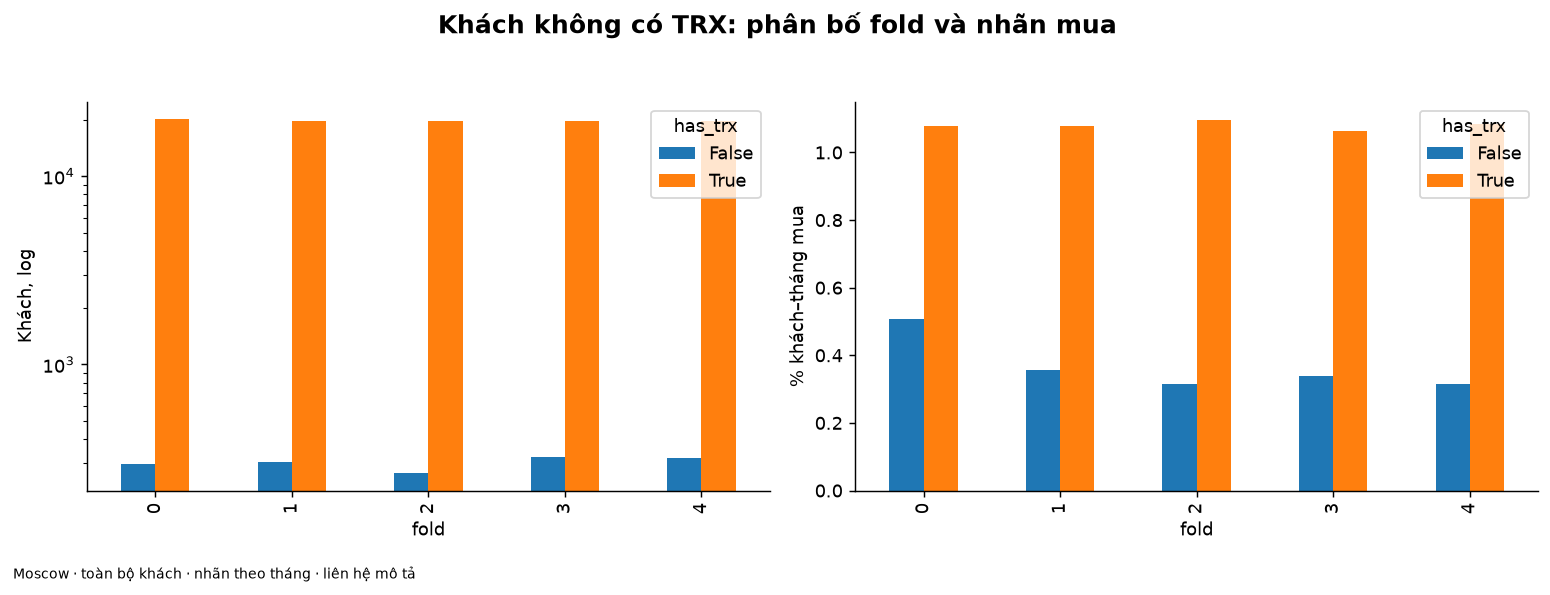

**outputs/eda_figures_moscow/trx_null_drift_moscow.png**

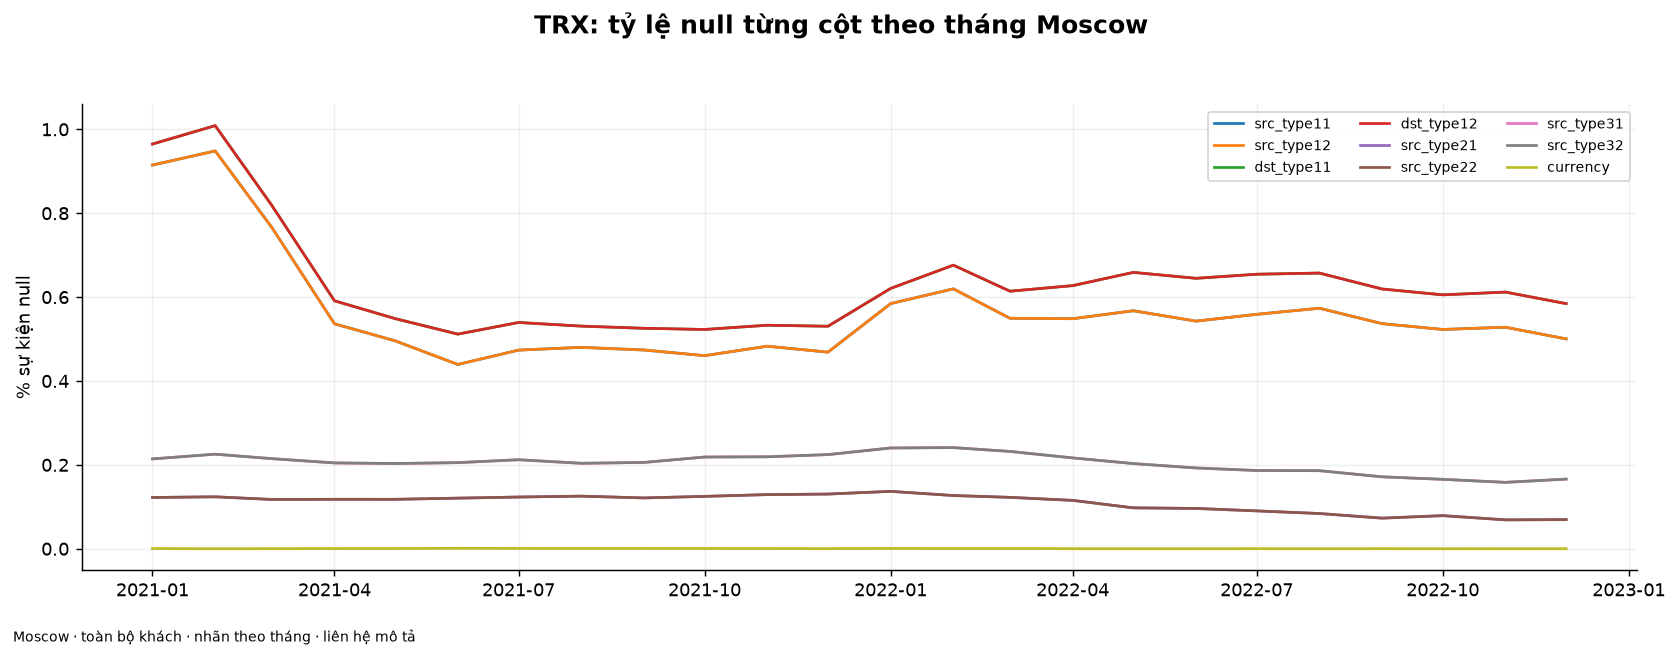

**outputs/eda_figures_moscow/figure_index.csv** — 5 dòng đầu

,figure,title,data,explanation
0,all_history_recency_by_purchase_month,Recency toàn lịch sử trước đầu tháng mua,all_history_recency_by_purchase_month.csv,all_history_recency_by_purchase_month.md
1,baseline_amount11,amount11: thay đổi so với nền của chính khách,baseline_amount11.csv,baseline_amount11.md
2,baseline_dialog,dialog: thay đổi so với nền của chính khách,baseline_dialog.csv,baseline_dialog.md
3,baseline_dialog_active_days,dialog_active_days: thay đổi so với nền của ch...,baseline_dialog_active_days.csv,baseline_dialog_active_days.md
4,baseline_dialog_reactivation_30d,dialog_reactivation_30d: thay đổi so với nền c...,baseline_dialog_reactivation_30d.csv,baseline_dialog_reactivation_30d.md


**outputs/eda_figures_moscow/trx_category_parent_structure.csv** — 5 dòng đầu

,child,parent,codes,multiple_parent_codes
0,event_subtype,event_type,60,57
1,src_type12,src_type11,262,0
2,dst_type12,dst_type11,322,0
3,src_type22,src_type21,85,82
4,src_type32,src_type31,86,84


**outputs/eda_figures_moscow/trx_customer_lorenz_ccdf.csv** — 5 dòng đầu

,metric,top_fraction,customers,share,gini,zero_customers
0,events,0.001,101,0.067851,0.651303,1503
1,events,0.010,1003,0.131572,0.651303,1503
2,events,0.100,10023,0.457530,0.651303,1503
3,amount11,0.001,101,0.746491,0.957078,1503
4,amount11,0.010,1003,0.828805,0.957078,1503


... (5 outputs left out)

,month,events,src_type11,src_type12,dst_type11,dst_type12,src_type21,src_type22,src_type31,src_type32,currency
0,2021-01-01,1453898,0.009148,0.009148,0.009649,0.009649,0.001222,0.001222,0.002142,0.002142,2.751225e-06
1,2021-02-01,1447665,0.009484,0.009484,0.010088,0.010088,0.001238,0.001238,0.002255,0.002255,6.907675e-07
2,2021-03-01,1632368,0.007662,0.007662,0.008187,0.008187,0.001175,0.001175,0.002148,0.002148,1.837821e-06
3,2021-04-01,1582180,0.005363,0.005363,0.005911,0.005911,0.001179,0.001179,0.002046,0.002046,2.528157e-06
4,2021-05-01,1582650,0.004957,0.004957,0.005486,0.005486,0.001178,0.001178,0.002032,0.002032,4.422961e-06


**outputs/eda_figures_moscow/trx_type_subtype_currency_all.csv** — 5 dòng đầu

,event_type,event_subtype,currency,events
0,16,18,11,41660
1,1,12,11,16563870
2,56,41,11,819000
3,7,23,11,177053
4,11,40,11,2835


File kết quả khác: `outputs/eda_figures_moscow/execution_status.json`, `outputs/eda_figures_moscow/trx_all_customer_concentration.parquet`, `outputs/eda_figures_moscow/trx_category_parent_structure.md`, `outputs/eda_figures_moscow/trx_customer_lorenz_ccdf.md`, `outputs/eda_figures_moscow/trx_fold_time_resolution.md`, `outputs/eda_figures_moscow/trx_missing_population_fold_purchase.md`, `outputs/eda_figures_moscow/trx_null_drift_moscow.md`

In [17]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_trx_quality.py')

## Check Trans Count Target History

Nguồn: `src/scripts/check_trans_count_target_history.py`. Chạy các ô của phần này theo thứ tự.

In [18]:
__file__ = str(ROOT / 'src/scripts/check_trans_count_target_history.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [19]:
"""Check whether source trans_count equals cumulative positive target labels."""
from pathlib import Path
import pandas as pd
import numpy as np
ROOT=Path(__file__).resolve().parents[2]; O=ROOT/'outputs/trans_count_target_history'; O.mkdir(exist_ok=True)
a=pd.read_parquet(ROOT/'outputs/dataset_eda/customer_month_snapshots.parquet',columns=['client_id','outcome_month','trans_count','y_any',*[f'target_{i}' for i in range(1,5)]]).sort_values(['client_id','outcome_month']).reset_index(drop=True)
assert not a.duplicated(['client_id','outcome_month']).any()
a['all_product_positives']=a[[f'target_{i}' for i in range(1,5)]].sum(axis=1)
rows=[]; monthly=[]
for col in ['y_any','all_product_positives',*[f'target_{i}' for i in range(1,5)]]:
 cum=a.groupby('client_id')[col].cumsum()
 for mode,v in [('prior_only',cum-a[col]),('including_current_diagnostic',cum)]:
  name=col+'_'+mode; same=a.trans_count.eq(v); a[name]=v
  for cohort,mask in [('all',np.ones(len(a),dtype=bool)),('exclude_first_observed_month',a.outcome_month.gt(a.outcome_month.min()).to_numpy()),('source_positive',a.trans_count.gt(0).to_numpy())]:
   rows.append(dict(candidate=name,cohort=cohort,rows=int(mask.sum()),exact=int(same[mask].sum()),match_pct=float(same[mask].mean()*100),candidate_max=float(v[mask].max()),source_max=int(a.loc[mask,'trans_count'].max()),mean_absolute_error=float((a.loc[mask,'trans_count']-v[mask]).abs().mean())))
  for month,idx in a.groupby('outcome_month').groups.items(): monthly.append(dict(candidate=name,month=str(month.date()),rows=len(idx),exact=int(same.loc[idx].sum()),match_pct=float(same.loc[idx].mean()*100)))
# Count distinct products ever positive before cutoff (rather than positive months).
prior_flags=[]
for i in range(1,5):
 col=f'target_{i}'; prior=(a.groupby('client_id')[col].cumsum()-a[col]).gt(0); prior_flags.append(prior.astype(int))
v=sum(prior_flags); a['distinct_products_prior']=v; same=a.trans_count.eq(v)
rows.append(dict(candidate='distinct_products_prior',cohort='all',rows=len(a),exact=int(same.sum()),match_pct=float(same.mean()*100),candidate_max=int(v.max()),source_max=int(a.trans_count.max()),mean_absolute_error=float((a.trans_count-v).abs().mean())))
r=pd.DataFrame(rows); r.to_csv(O/'candidate_summary.csv',index=False); pd.DataFrame(monthly).to_csv(O/'candidate_by_month.csv',index=False)
a.loc[a.trans_count.gt(a.all_product_positives_including_current_diagnostic)].head(30).to_csv(O/'counterexamples.csv',index=False)
summary={'rows':len(a),'clients':a.client_id.nunique(),'observed_label_months':a.outcome_month.nunique(),'source_exceeds_all_observed_product_positives_to_current':int(a.trans_count.gt(a.all_product_positives_including_current_diagnostic).sum()),'first_month_positive_trans_count':int(a.loc[a.outcome_month.eq(a.outcome_month.min()),'trans_count'].gt(0).sum()),'caveat':'Targets are binary monthly indicators, not purchase transaction counts. Earlier purchase history before the first label month is unobserved; cannot reject a definition using unavailable history.'}
import json
(O/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
print(r[r.cohort=='all'][['candidate','exact','match_pct','candidate_max']].to_string(index=False)); print(summary)

                                         candidate  exact  match_pct  candidate_max
                                  y_any_prior_only 120217   9.995693            7.0
                y_any_including_current_diagnostic 118745   9.873300            8.0
                  all_product_positives_prior_only 120210   9.995111            8.0
all_product_positives_including_current_diagnostic 118742   9.873051            8.0
                               target_1_prior_only 120300  10.002594            5.0
             target_1_including_current_diagnostic 119151   9.907058            5.0
                               target_2_prior_only 120781  10.042588            6.0
             target_2_including_current_diagnostic 120772  10.041840            6.0
                               target_3_prior_only 120716  10.037183            4.0
             target_3_including_current_diagnostic 120497  10.018974            4.0
                               target_4_prior_only 120730  10.038347        

In [20]:
show_generated_results(__eda_started_ns, 'src/scripts/check_trans_count_target_history.py')

### Kết quả: `src/scripts/check_trans_count_target_history.py`

**outputs/trans_count_target_history/candidate_by_month.csv** — 5 dòng đầu

,candidate,month,rows,exact,match_pct
0,y_any_prior_only,2022-02-01,100224,26489,26.429797
1,y_any_prior_only,2022-03-01,100224,19751,19.706857
2,y_any_prior_only,2022-04-01,100224,16059,16.023108
3,y_any_prior_only,2022-05-01,100224,13428,13.397989
4,y_any_prior_only,2022-06-01,100224,11564,11.538155


**outputs/trans_count_target_history/candidate_summary.csv** — 5 dòng đầu

,candidate,cohort,rows,exact,match_pct,candidate_max,source_max,mean_absolute_error
0,y_any_prior_only,all,1202688,120217,9.995693,7.0,1000,96.021713
1,y_any_prior_only,exclude_first_observed_month,1102464,93728,8.501684,7.0,1000,103.750565
2,y_any_prior_only,source_positive,1081902,759,0.070154,7.0,1000,106.740532
3,y_any_including_current_diagnostic,all,1202688,118745,9.873300,8.0,1000,96.013887
4,y_any_including_current_diagnostic,exclude_first_observed_month,1102464,92415,8.382587,8.0,1000,103.742626


**outputs/trans_count_target_history/counterexamples.csv** — 5 dòng đầu

,client_id,outcome_month,trans_count,y_any,target_1,target_2,target_3,target_4,all_product_positives,y_any_prior_only,...,all_product_positives_including_current_diagnostic,target_1_prior_only,target_1_including_current_diagnostic,target_2_prior_only,target_2_including_current_diagnostic,target_3_prior_only,target_3_including_current_diagnostic,target_4_prior_only,target_4_including_current_diagnostic,distinct_products_prior
0,000032cc38caee45fe031778bcf6af05aa2aabe476acb8...,2022-03-01,8,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,000032cc38caee45fe031778bcf6af05aa2aabe476acb8...,2022-04-01,23,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,000032cc38caee45fe031778bcf6af05aa2aabe476acb8...,2022-05-01,32,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,000032cc38caee45fe031778bcf6af05aa2aabe476acb8...,2022-06-01,36,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,000032cc38caee45fe031778bcf6af05aa2aabe476acb8...,2022-07-01,38,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


File kết quả khác: `outputs/trans_count_target_history/summary.json`